## Cellpose Usage
Original Cellpose-SAM article: https://www.biorxiv.org/content/10.1101/2025.04.28.651001v1.full.pdf  

### Cellpose install
See: https://github.com/mouseland/cellpose
Note that cellpose can be installed in an existing conda env or venv using 'python -m pip install cellpose[gui]' (once env is activated)

### GUI activation (with GPU)
Enter in powershell to activate:  
`cellpose\Scripts\activate`  
`cellpose`
note: if you run with venv it will not use GPU

### Terminal deployment (with GPU, for batch processing)
Run below lines in powershell to run cellpose without gui, using GPU. Enables batch processing.  

If needed, create venv with compatible python (v.13 and later are NOT compatible with cellpose gpu usage thus had to create dedicated venv w 3.11).  
`py -3.11 -m venv .venv311 `  
Activate venv  
`.venv311\Scripts\Activate.ps1 ` 
Note: Before generating masks for all images, strongly recommended to test a few in the GUI!

Run cellpose on folder of tifs (pngs/jpegs should work too)
For example:
`cellpose --dir D:\LNP\Mich2data\28-07-2026_Huh7_HepG2_chloro_96well\20X\A1,0-24h,tifs --pretrained_model cyto --diameter 130 --min_size 20 --use_gpu --verbose niter=500`
Note: cellpose gui also installed under the .venv
Note: diameter~50 for 10X, diameter ~100 for 20x
Note: NO SPACES allowed in any file paths

### Custom models
Follow: https://cellpose.readthedocs.io/en/latest/train.html 
Custom model trained on 8 manually annotated FOVs of Huh7 cells from Jul 2026 exp located: "D:\LNP\Mich2data\30-07-2026_Huh7_oldLNP\tifs\CellposeTraining\cpsam_20260730_Huh7_8fov"
cellpose --dir D:\LNP\Mich2data\10-08-2026_Huh7_nanowells\no-offset --pretrained_model D:\LNP\Mich2data\30-07-2026_Huh7_oldLNP\tifs\CellposeTraining\cpsam_20260730_Huh7_8fov --diameter 130 --min_size 20 --use_gpu --save_png --verbose --niter 600

#### Segmentation Parameters  
--flow_threshold (default ~0.4, set to 0.0 to permit all masks)   
(higher = stricter segmentation, fewer merges)  
--cellprob_threshold (default 0.0, range -6 to 6; lower is better for this application)   
--diameter: expected cell size in pixels (avoid auto-estimation)  
--min_size: in pixels, remove small junk objects  
--resample: improves mask boundaries (slower but better)  

--invert: use for brightfield images  
--tile: split large images into tiles  
--stitch_threshold: merge objects across tiles  
--do_3D: enable for Z-stacks only  
--anisotropy: Z scaling factor for 3D data  

#### Saving
--save_png: saves png of mask
--save_tif: saves tif of mask  
--save_flows: flow fields  
--save_outlines: mask outlines  
--no_npy: disable .npy files  

Notes:  
* will not overwrite existing files of same name, simply won't generate output
* must have cellpose package installed in venv equipped for GPU
* fairly computationally intensive thus good to check mask generation on sample images in GUI first before running batches

In [ ]:
# enter this in command line to activate cellpose gui (nice for testing and tuning but can't run in bulk)
cellpose\Scripts\activate
cellpose # opens gui

# run below lines in powershell to run cellpose without gui, using GPU
# create venv with compatible python (v.13 and later are NOT compatible with cellpose gpu usage thus had to create dedicated venv w 3.11)
py -3.11 -m venv .venv311 
# activate venv
.venv311\Scripts\Activate.ps1 
# run cellpose on folder of tifs/pngs/jpegs
cellpose --dir D:/Sadie/HepG2/test/cellline1 --pretrained_model cyto --chan 0 --diameter 40 --save_png --use_gpu --verbose
# failed attempts:
# can also enter below in powershell with cellpose venv activated but can't use gpu
python -m cellpose --dir D:/Sadie/HepG2/test/cellline1 --pretrained_model cyto --chan 0 --diameter 40 --save_png --use_gpu 
# tried importing 'models' from cellpose package to run in py block but errored

In [ ]:
from cellpose import models
from cellpose.io import imread
import numpy as np
from cellpose import plot, utils, io
import matplotlib.pyplot as plt

from pathlib import Path

directory = Path(r"D:\your\directory")

for path in directory.glob("*_cp_masks.png"):
    new_path = path.with_name(path.name.replace("_cp_masks.png", "_mask.png"))
    path.rename(new_path)

In [ ]:
model = models.CellposeModel(gpu=True)
img = io.imread(r"D:\LNP\Mich2data\30-07-2026_Huh7_oldLNP\tifs\20260730_11h00_WellA06_ChannelmCherry,GFP,20X Phase_Seq2.tif")
masks, flows, styles, diams = model.eval(img, flow_threshold=0.4, cellprob_threshold=0.0)

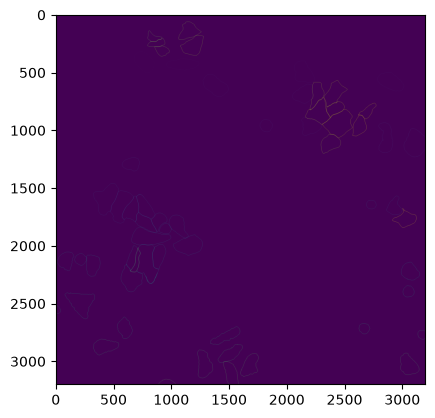

In [6]:
dat = np.load(r'D:\LNP\Mich2data\30-07-2026_Huh7_oldLNP\tifs\20260730_11h00_WellA06_ChannelmCherry,GFP,20X Phase_Seq0_seg.npy', allow_pickle=True).item()
plt.imshow(dat['outlines'])

In [ ]:
plt.imshow(dat['masks'])

In [1]:
plt.imshow(dat['flows'][1][0])
pass

NameError: name 'plt' is not defined